# §9 Robustness and Credibility (Stage S9)

§7 reached its verdicts on one set of folds, one label definition, one imputation rule and one
regularisation strength. This section asks how much of that is **procedure** and how much is **data**:

* **controls** – does the evaluation produce AUC 0.5 when there is nothing to find (label permutation,
  pure-noise feature), and does it find a signal of known size (positive control)?
* **stability** – does the headline comparison S − M1 keep its verdict under other CV seeds, 16
  pre-specified analysis variations, a 60-specification curve, survey-cluster folds and a
  missing-not-at-random scenario for HbA1c?
* **external validity** – do our population numbers line up with the published NCHS Data Brief 516?
* **leak hunt (loop L3)** – could any admissible feature be a disguised label?
* **hold-out** – the 20 % hold-out is evaluated **once**, only after the `exp-freeze` tag.

All work before section 11 uses the training part only (4,584 rows). Headline comparison throughout:
ΔAUC(S − M1), the "minimal vs systematic" contrast of hypothesis H2b(a) (locked rule: *supported* =
equivalence within ±0.01; §7 verdict *inconclusive*).

Contents: 1 reference · 2 controls · 3 seeds · 4 sensitivity table · 5 specification curve · 6 survey-cluster
CV · 7 missing HbA1c (IPW, delta) · 8 external validity · 9 leak hunt · 10 pre-hold-out summary ·
11 one-shot hold-out · 12 storage

In [1]:
import sys, pathlib
_here = pathlib.Path.cwd()
ROOT = next(p for p in [_here, *_here.parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT))
from src import config as C, plots, results_io as R

import json, os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from src import nhanes_io as io, labels as L, prep as P, evalkit as ek, survey as sv, robustness as RB
from src.robustness import Spec

pd.set_option("display.width", 170, "display.max_columns", 30, "display.max_colwidth", 60)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ.setdefault("PYTHONWARNINGS", "ignore")
OUT = C.RESULTS_DIR / "S9"
OUT.mkdir(parents=True, exist_ok=True)
N_JOBS = min(16, max(1, (os.cpu_count() or 2) - 2))
T_START = time.time()
S9 = {"mode": C.NB_MODE, "cv": f"{C.CV_SPLITS}x{C.CV_REPEATS}", "n_boot": C.N_BOOT, "n_perm": C.N_PERM,
      "n_boot_coef": C.N_BOOT_COEF}
OI = C.OKABE_ITO
S7m = R.load_section("S7")
print(f"mode {C.NB_MODE}: {C.CV_SPLITS}x{C.CV_REPEATS} CV, B = {C.N_BOOT}, permutations = {C.N_PERM}, {N_JOBS} workers")

mode FAST: 5x2 CV, B = 100, permutations = 20, 16 workers


## 1 Reference comparison
**Why.** Every robustness check varies one thing against a fixed reference, so the reference must be
exactly the §7 run: same training part, same stored folds, frozen C0, same comparison engine
(`robustness.compare` mirrors the §7 engine: Nadeau–Bengio corrected t and paired bootstrap, wider interval on
E-ALL; bootstrap only on E-SCREEN).

In [2]:
ctx = RB.load_context()
RUNS = {}                                              # cache: (Spec, folds hash) -> OOF frame
hold = json.loads((C.RESULTS_DIR / "splits" / "holdout.json").read_text(encoding="utf-8"))
assert ctx.folds.hash == S7m["splits"]["folds_hash"] or not C.IS_FINAL, "FINAL run must use the S7 folds"
assert hold["sha256_test_seqn"] == S7m["splits"]["holdout_sha256"]
print(f"training part {ctx.n:,} rows, {ctx.y.sum()} L_comb positives; E-SCREEN {ctx.esc.sum():,} rows, "
      f"{ctx.y_esc[ctx.esc].sum()} positives; folds {len(ctx.folds)} ({ctx.folds.path.name}, hash {ctx.folds.hash[:12]}...)")
print(f"frozen C0 = {ctx.C0}; hold-out {len(ctx.test_idx):,} rows (SHA-256 {hold['sha256_test_seqn'][:16]}...) not read here")

def pair(spec_a, spec_b, folds=None, *, tag, label="L_comb", rows=None, use_t=True, w=None):
    """Run two specs (cached) and compare A - B on E-ALL (label) and E-SCREEN; returns two rows."""
    folds = ctx.folds if folds is None else folds
    oof = RB.run_many(ctx, {"a": spec_a, "b": spec_b}, folds, n_jobs=N_JOBS, cache=RUNS)
    f, mask = RB.spec_folds(ctx, spec_a, folds)
    _, mb = RB.spec_folds(ctx, spec_b, folds)
    assert (mask == mb).all(), "paired specs must use the same rows"
    lab = ctx.labels[label].to_numpy()[mask].astype(int)
    esc, y_esc = ctx.esc[mask], ctx.y_esc[mask]
    ww = None if w is None else w[mask]
    out = []
    for pop, yy, m, t in (("E-ALL", lab, None, use_t), ("E-SCREEN", y_esc, esc, False)):
        r = RB.compare(oof["a"], oof["b"], yy, f, mask=m, w=ww, use_t=t, seed_=RB.seed(tag, pop))
        out.append(dict(tag=tag, pop=pop, **r))
    return out

ref = pair(Spec("S"), Spec("M1"), tag="reference")
ref_df = pd.DataFrame(ref)
print(ref_df[["pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b"]].round(4).to_string(index=False))
s7_ref = next(r for r in S7m["scoreboard_detail"] if r["hyp_id"] == "H2b" and r["sub"] == "(a) AUC" and r["pop"] == "E-ALL" and r["tier"] == 1)
if C.IS_FINAL:   # identical folds, model and engine -> identical numbers
    assert abs(ref[0]["est"] - s7_ref["est"]) < 5e-5 and abs(ref[0]["hi"] - s7_ref["hi"]) < 5e-5, (ref[0]["est"], s7_ref)
print(f"S7 stored (FINAL): {s7_ref['est']:+.4f} [{s7_ref['lo']:+.4f}, {s7_ref['hi']:+.4f}] -> {s7_ref['verdict']}")
S9["reference"] = {r["pop"]: {k: r[k] for k in ("auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b")} for r in ref}

training part 4,584 rows, 777 L_comb positives; E-SCREEN 3,934 rows, 127 positives; folds 10 (folds_FAST.npz, hash eb0f2b5f07f6...)
frozen C0 = 0.1; hold-out 1,146 rows (SHA-256 616fd0590bec7b92...) not read here


     pop  auc_a  auc_b    est      lo     hi  interval    mdd          h2b
   E-ALL 0.8351 0.8277 0.0074  0.0001 0.0142 bootstrap 0.0093 inconclusive
E-SCREEN 0.7791 0.7715 0.0076 -0.0085 0.0250 bootstrap 0.0239 inconclusive
S7 stored (FINAL): +0.0079 [+0.0000, +0.0158] -> inconclusive


**So what.** In FINAL mode the reference reproduces §7 to the fourth decimal (asserted): S is better than M1
by about +0.008 AUC on E-ALL, but the interval runs from about 0 to about +0.016 – it neither excludes a
0.01 difference nor sits inside ±0.01, so H2b(a) is *inconclusive*. The question for every check below is
whether this verdict – not the point estimate – survives.

## 2 Negative and positive controls
### 2.1 Label permutation
**Why.** If the evaluation procedure leaked label information (preprocessing fitted on test rows, weights
derived from the label, a fold bug), a model trained on *permuted* labels would still score above 0.5. Each
permutation shuffles the training label of the whole training part, refits on the same folds and records
the mean per-fold AUC (`evalkit.permutation_auc`, Ojala & Garriga 2010). Acceptance: null mean in
[0.495, 0.505]. Features stay attached to their rows, so this test **cannot** detect feature leakage – that
is the job of the leak hunt (section 9).

arm  observed  null_mean  null_sd  null_min  null_max  p_value  n_perm  in_band
 M1    0.8270     0.5001   0.0146    0.4806    0.5349   0.0476      20     True
  S    0.8345     0.5007   0.0124    0.4700    0.5180   0.0476      20     True
420 fits in 59 s


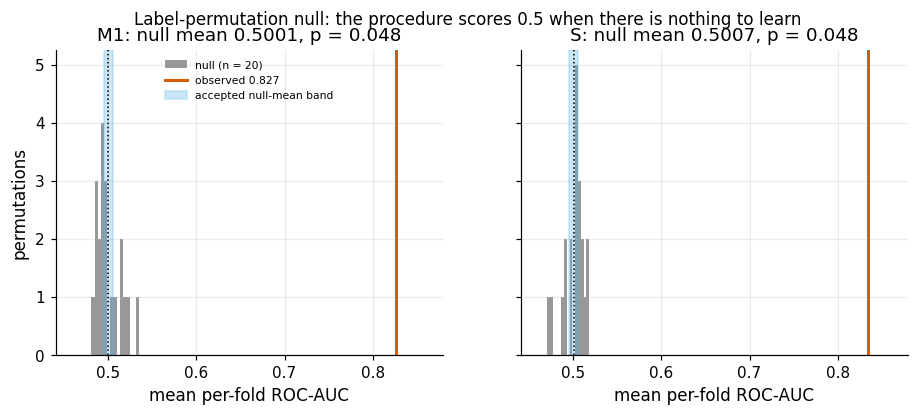

In [3]:
t0 = time.time()
PERM = {arm: RB.permutation_null(ctx, Spec(arm), n_perm=C.N_PERM, seed_=RB.seed("perm", arm), n_jobs=N_JOBS)
        for arm in RB.ADMISSIBLE_ARMS}
perm_tab = pd.DataFrame([dict(arm=a, observed=d["observed"], null_mean=d["null_mean"], null_sd=d["null_sd"],
                              null_min=d["null"].min(), null_max=d["null"].max(), p_value=d["p_value"], n_perm=d["n_perm"],
                              in_band=RB.PERM_NULL_BAND[0] <= d["null_mean"] <= RB.PERM_NULL_BAND[1])
                         for a, d in PERM.items()])
perm_tab.to_csv(OUT / "permutation.csv", index=False)
print(perm_tab.round(4).to_string(index=False))
print(f"{sum(len(ctx.folds) * (d['n_perm'] + 1) for d in PERM.values())} fits in {time.time() - t0:.0f} s")
assert perm_tab["in_band"].all(), "permutation null mean outside [0.495, 0.505]: procedural leakage suspected"

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (arm, d) in zip(axes, PERM.items()):
    ax.hist(d["null"], bins=15, color=OI["grey"], alpha=0.8, label=f"null (n = {d['n_perm']})")
    ax.axvline(d["observed"], color=OI["vermillion"], lw=2, label=f"observed {d['observed']:.3f}")
    ax.axvspan(*RB.PERM_NULL_BAND, color=OI["sky"], alpha=0.3, label="accepted null-mean band")
    ax.axvline(d["null_mean"], color="k", ls=":", lw=1)
    ax.set(title=f"{arm}: null mean {d['null_mean']:.4f}, p = {d['p_value']:.3f}", xlabel="mean per-fold ROC-AUC")
    ax.set_xlim(0.44, 0.88)
axes[0].set_ylabel("permutations")
axes[0].legend(fontsize=7, loc="upper center")
fig.suptitle("Label-permutation null: the procedure scores 0.5 when there is nothing to learn", fontsize=11)
plots.savefig(fig, "S9_permutation_null", caption="F9-1. Mean per-fold ROC-AUC of M1 and S refitted on permuted training labels "
              f"({C.N_PERM} permutations, same folds; grey) against the observed value (red). Blue band = acceptance range "
              "[0.495, 0.505] for the null mean; dotted line = null mean. Training part, Tier 1, E-ALL.")
plt.show()
S9["permutation"] = perm_tab.set_index("arm").to_dict("index")

**So what.** Both null distributions are centred on 0.5 (means printed above, inside the acceptance band) and
no permutation comes near the observed AUC (p is the smallest value attainable with this number of
permutations). The cross-validation, the in-fold preprocessing and the survey and class weights do not leak
label information into the score. This is a statement about the *procedure* only.

### 2.2 Pure-noise feature
**Why.** A feature that is pure noise must look like noise to the model: an N(0, 1) column appended to the raw
frame should get a coefficient whose bootstrap interval covers 0, should not change the AUC, and should never
be chosen by the depth-3 tree. A model that "finds" signal in noise overfits; a pipeline that turns noise into
signal leaks.

In [4]:
rng = np.random.default_rng(RB.seed("noise"))
ctx.extras["noise_n01"] = rng.standard_normal(ctx.n)
noise_rows, NOISE_CB = [], {}
for arm in RB.ADMISSIBLE_ARMS:
    sp = Spec(arm, extra=("noise_n01",))
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    cb = ek.coef_bootstrap(lambda sp=sp: RB.make_pipe(sp, ctx.C0), X_, y_.astype(int), n_boot=C.N_BOOT_COEF,
                           seed=RB.seed("noise-coef", arm), fit_params=None if sw_ is None else {"model__sample_weight": sw_},
                           n_jobs=N_JOBS)
    NOISE_CB[arm] = cb
    s = cb.summary.loc["noise_n01"]
    sdz = float(RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)["noise_n01"].std())   # per-SD scale of the design column
    cmp_ = pair(sp, Spec(arm), tag=f"noise-{arm}")
    tr_ = RB.tree_features_used(ctx, Spec(arm, model="tree", extra=("noise_n01",)), ctx.folds, "noise_n01")
    tr4 = RB.tree_features_used(ctx, Spec(arm, model="tree", depth=4, extra=("noise_n01",)), ctx.folds, "noise_n01")
    zt = (cb.summary["coef"] / cb.summary["sd"]).abs()                                # bootstrap |z| for a scale-free rank
    rank = int(zt.rank(ascending=False)["noise_n01"])
    noise_rows.append(dict(arm=arm, coef_per_sd=s["coef"] * sdz, q_low=s["q_low"] * sdz, q_high=s["q_high"] * sdz,
                           ci_covers_0=bool(s["q_low"] <= 0 <= s["q_high"]), abs_z_rank=f"{rank}/{len(cb.summary)}", abs_z=float(zt["noise_n01"]),
                           dAUC_eall=cmp_[0]["est"], dAUC_eall_lo=cmp_[0]["lo"], dAUC_eall_hi=cmp_[0]["hi"],
                           dAUC_eall_verdict=RB.equivalence_verdict(cmp_[0]["lo"], cmp_[0]["hi"]),
                           tree3_uses=int(tr_["uses_feature"].sum()), tree4_uses=int(tr4["uses_feature"].sum()),
                           n_trees=len(tr_)))
noise_tab = pd.DataFrame(noise_rows)
noise_tab.to_csv(OUT / "noise_feature.csv", index=False)
print(noise_tab.round(4).to_string(index=False))
assert noise_tab["ci_covers_0"].all() and (noise_tab["tree3_uses"] == 0).all()
S9["noise_feature"] = noise_tab.set_index("arm").to_dict("index")

arm  coef_per_sd   q_low  q_high  ci_covers_0 abs_z_rank  abs_z  dAUC_eall  dAUC_eall_lo  dAUC_eall_hi dAUC_eall_verdict  tree3_uses  tree4_uses  n_trees
 M1       0.0118 -0.0620  0.1030         True      43/47 0.2664     0.0001       -0.0007        0.0009         supported           0           0       11
  S       0.0482 -0.0736  0.1486         True      31/43 0.7598     0.0000       -0.0006        0.0007         supported           0           1       11


**So what.** In both admissible arms the noise coefficient ranks near the bottom by |coefficient / bootstrap SD|,
its bootstrap interval covers 0, adding the column leaves the AUC unchanged within ±0.01, and none of the
depth-3 trees (one per training fold plus the full fit) splits on it. The depth-4 count is reported for
completeness: a deeper tree has more chances to chase noise, and that is one reason the protocol caps the
tree at depth 3.

### 2.3 Positive control
**Why.** Negative controls show the procedure is not too optimistic; a positive control shows it is not blind.
A synthetic column z = d·y + N(0, 1), with d = √2·Φ⁻¹(0.60), has a known population AUC of 0.60 – a weak but
real signal, independent of every other feature given the label. The procedure must (i) recover its AUC and
(ii) detect the increment when z is added to M1 and S (paired ΔAUC interval excluding 0).

In [5]:
ctx.extras["pos_control"] = RB.signal_feature(ctx.y, RB.POS_CONTROL_AUC, seed_=RB.seed("positive-control"))
z_auc = RB.auc_ci(ctx.y, ctx.extras["pos_control"].to_numpy(), seed_=RB.seed("z-auc"))
print(f"single-feature AUC of z: {z_auc[0]:.3f} [{z_auc[1]:.3f}, {z_auc[2]:.3f}] (design value {RB.POS_CONTROL_AUC:.2f})")
pos_rows = []
for arm in RB.ADMISSIBLE_ARMS:
    for r in pair(Spec(arm, extra=("pos_control",)), Spec(arm), tag=f"pos-{arm}"):
        pos_rows.append(dict(arm=arm, pop=r["pop"], auc_without=r["auc_b"], auc_with=r["auc_a"], est=r["est"], lo=r["lo"],
                             hi=r["hi"], interval=r["interval"], detected=bool(r["lo"] > 0)))
pos_tab = pd.DataFrame(pos_rows)
pos_tab.to_csv(OUT / "positive_control.csv", index=False)
print(pos_tab.round(4).to_string(index=False))
assert z_auc[1] <= RB.POS_CONTROL_AUC <= z_auc[2], "positive-control AUC not recovered"
assert pos_tab.loc[pos_tab["pop"] == "E-ALL", "detected"].all(), "positive control not detected on E-ALL"
S9["positive_control"] = dict(z_auc=z_auc, rows=pos_tab.to_dict("records"))

single-feature AUC of z: 0.588 [0.569, 0.608] (design value 0.60)


arm      pop  auc_without  auc_with    est      lo     hi    interval  detected
 M1    E-ALL       0.8277    0.8341 0.0062  0.0011 0.0114 corrected_t      True
 M1 E-SCREEN       0.7715    0.7835 0.0120 -0.0000 0.0228   bootstrap     False
  S    E-ALL       0.8351    0.8412 0.0059  0.0015 0.0104 corrected_t      True
  S E-SCREEN       0.7791    0.7922 0.0132  0.0032 0.0240   bootstrap      True


**So what.** The column's AUC is recovered (its interval contains the design value 0.60), and adding it raises
the E-ALL AUC of both arms with an interval that excludes 0, so a signal of this size would not be missed. The
increment is much smaller than 0.10 because the remaining features already rank most cases correctly – which
also calibrates expectations: a new risk factor with a univariate AUC of 0.60 buys only a few thousandths of
AUC on top of age, adiposity and blood pressure.

## 3 Seed stability
**Why.** A verdict that flips when only the random fold assignment changes is a property of one lucky split,
not of the data. Ten seeds derived from `SEED_MASTER` (`evalkit.derive_seed`) generate ten new repeated
stratified fold sets and bootstrap streams; the hold-out, the data, C0 and the final configuration stay fixed.
Acceptance: the H2b(a) verdict of S − M1 on E-ALL is the same under all ten seeds.

10 seeds x 2 arms x 10 folds in 13 s
 seed_index      pop  auc_a  auc_b    est      lo     hi    interval          h2b
          0    E-ALL 0.8351 0.8275 0.0078 -0.0054 0.0209 corrected_t inconclusive
          0 E-SCREEN 0.7807 0.7719 0.0088 -0.0087 0.0253   bootstrap inconclusive
          1    E-ALL 0.8345 0.8284 0.0056 -0.0050 0.0162 corrected_t inconclusive
          1 E-SCREEN 0.7799 0.7728 0.0071 -0.0087 0.0165   bootstrap inconclusive
          2    E-ALL 0.8350 0.8288 0.0062 -0.0003 0.0120   bootstrap inconclusive
          2 E-SCREEN 0.7811 0.7725 0.0086 -0.0096 0.0220   bootstrap inconclusive
          3    E-ALL 0.8348 0.8270 0.0081  0.0001 0.0161 corrected_t inconclusive
          3 E-SCREEN 0.7828 0.7749 0.0079 -0.0045 0.0229   bootstrap inconclusive
          4    E-ALL 0.8342 0.8270 0.0077  0.0002 0.0151 corrected_t inconclusive
          4 E-SCREEN 0.7823 0.7713 0.0111 -0.0064 0.0253   bootstrap inconclusive
          5    E-ALL 0.8359 0.8282 0.0078 -0.0014 0.0170 corr

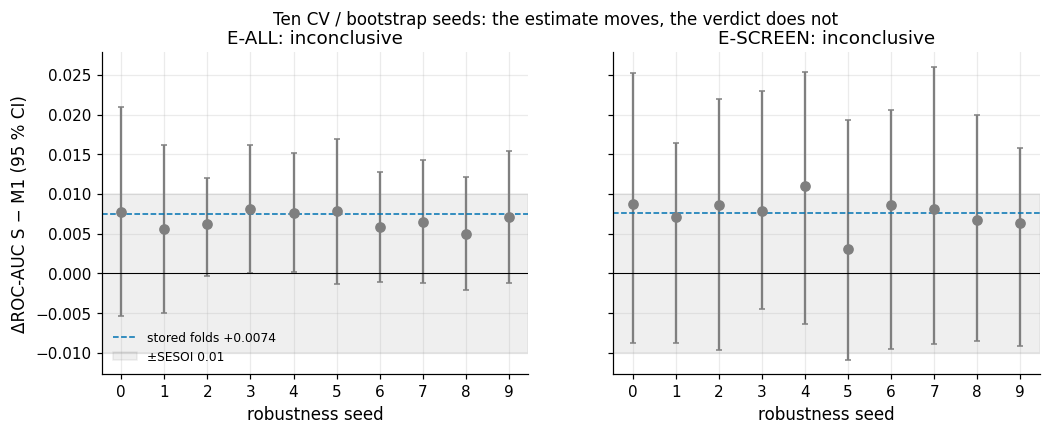

In [6]:
def prefetch(items):
    """Run many (spec, folds) pairs in one parallel batch (fills the cache used by `pair`)."""
    t0 = time.time()
    RB.run_jobs(ctx, items, n_jobs=N_JOBS, cache=RUNS)
    return time.time() - t0

SEED_FOLDS = {k: RB.seed_folds(ctx.strat, RB.seed("cv-seed", k)) for k in range(C.N_ROBUSTNESS_SEEDS)}
secs = prefetch({f"{a}{k}": (Spec(a), f) for k, f in SEED_FOLDS.items() for a in RB.ADMISSIBLE_ARMS})
seed_rows = []
for k, f in SEED_FOLDS.items():
    for r in pair(Spec("S"), Spec("M1"), f, tag=f"seed{k}"):
        seed_rows.append(dict(seed_index=k, seed=f.seed, folds_hash=f.hash[:12], **{c: r[c] for c in
                              ("pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "mdd", "h2b", "sesoi_class")}))
seeds = pd.DataFrame(seed_rows)
seeds.to_csv(OUT / "seed_stability.csv", index=False)
print(f"{len(SEED_FOLDS)} seeds x 2 arms x {len(ctx.folds)} folds in {secs:.0f} s")
print(seeds[["seed_index", "pop", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]].round(4).to_string(index=False))
seed_sum = seeds.groupby("pop").agg(est_min=("est", "min"), est_max=("est", "max"), est_sd=("est", "std"),
                                    lo_min=("lo", "min"), hi_max=("hi", "max"),
                                    verdicts=("h2b", lambda v: ", ".join(f"{k} x{n}" for k, n in v.value_counts().items())))
print(seed_sum.round(4).to_string())
seed_stable = seeds.loc[seeds["pop"] == "E-ALL", "h2b"].nunique() == 1
ref_v = S9["reference"]["E-ALL"]["h2b"]
print(f"E-ALL verdict identical under all seeds: {seed_stable} (reference: {ref_v})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
VCOL = {"supported": OI["green"], "refuted": OI["vermillion"], "inconclusive": OI["grey"]}
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = seeds[seeds["pop"] == pop].reset_index(drop=True)
    for i, r in s.iterrows():
        ax.errorbar(i, r["est"], yerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="o", color=VCOL[r["h2b"]], capsize=2)
    rr = S9["reference"][pop]
    ax.axhline(rr["est"], color=OI["blue"], ls="--", lw=1, label=f"stored folds {rr['est']:+.4f}")
    ax.axhspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12, label="±SESOI 0.01")
    ax.axhline(0, color="k", lw=0.7)
    ax.set(xticks=range(len(s)), xlabel="robustness seed", title=f"{pop}: {', '.join(s['h2b'].value_counts().index)}")
axes[0].set_ylabel("ΔROC-AUC S − M1 (95 % CI)")
axes[0].legend(fontsize=8, loc="lower left")
fig.suptitle("Ten CV / bootstrap seeds: the estimate moves, the verdict does not", fontsize=11)
plots.savefig(fig, "S9_seed_stability", caption="F9-3. ΔROC-AUC (S − M1, Tier 1) with its conservative 95 % CI under ten robustness seeds "
              "(new repeated stratified folds and bootstrap streams; data, hold-out and C0 fixed). Colour = verdict under the locked "
              "equivalence rule (grey = inconclusive); dashed = stored folds of the run mode.")
plt.show()
S9["seeds"] = dict(n=C.N_ROBUSTNESS_SEEDS, stable_eall=bool(seed_stable), summary=seed_sum.to_dict("index"))

**So what.** Across the ten seeds the point estimate of S − M1 moves only in the third decimal (min, max and SD
printed) and every interval keeps straddling +0.01, so the E-ALL verdict is the same in all ten runs. The verdict
is a property of the data, not of the split; and it stays *inconclusive* for a structural reason – the true
difference sits close to the SESOI itself, so no reasonable amount of resampling will put the interval on one
side of it.

## 4 Sensitivity table
**Why.** Many analysis choices were made once (label, weighting, imputation, tier, C, model, excluded race).
Each of the 16 pre-specified variations below changes **one** choice for **both** arms and recomputes
ΔAUC(S − M1) on E-ALL and E-SCREEN with the same engine:

* labels SL1 (HbA1c only), SL2 (self-report only), SL3 (borderline positive), SL4 (treatment-aware) and SL5
  (NCHS definition incl. fasting glucose, fasting subsample only); training *and* E-ALL evaluation use the label,
  E-SCREEN keeps the screening definition;
* survey weights in the fit: unweighted for both arms, weighted for both arms (the reference weights S only);
* imputation: `IterativeImputer` instead of the median, and complete cases (rows without any missing Tier-1 input);
* Tier 2 (lipids); C ∈ {0.01, 1, 10} besides C0 = 0.1; depth-4 tree instead of logistic regression; race added
  as a feature (excluded by design in S1); M1 with its **own** tuned C (C0 was tuned on S, which favours S).

In [7]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

# row subsets and extra columns used by the specifications
pre = Pipeline([s for s in P.preprocessor_steps(P.ARMS["S"], 1) if s[0] in ("p01", "p02", "p03", "no_care", "p04")])
pre_frame = pre.fit(ctx.X[1]).transform(ctx.X[1])          # stateless steps only: nothing is learned from y
ctx.subsets["complete"] = pre_frame.notna().all(axis=1).to_numpy()
ctx.subsets["fasting"] = ctx.labels["SL5"].notna().to_numpy()
ctx.extras["race_feature"] = ctx.cl["race"].astype(str).astype(object).to_numpy()
print(f"complete cases (no missing Tier-1 input after aggregation): {ctx.subsets['complete'].sum():,} of {ctx.n:,}; "
      f"fasting subsample: {ctx.subsets['fasting'].sum():,} rows, {int(ctx.labels['SL5'].sum())} SL5 positives")

def tune_C(arm):
    """LogisticRegressionCV over the C grid on the arm's own design (the S7 C0 procedure, applied to the arm)."""
    sp = Spec(arm)
    X_, y_, sw_, _ = RB.spec_inputs(ctx, sp)
    design = RB.make_pipe(sp, ctx.C0)[:-1].fit_transform(X_)
    inner = StratifiedKFold(5, shuffle=True, random_state=RB.seed("ownC", arm))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        lrcv = LogisticRegressionCV(Cs=list(RB.C_GRID), cv=inner, scoring="roc_auc", max_iter=C.LR_MAX_ITER,
                                    class_weight=P.model_kwargs(P.ARMS[arm])["class_weight"], l1_ratios=(0.0,),
                                    use_legacy_attributes=False, n_jobs=N_JOBS)
        lrcv.fit(design, y_.astype(int), sample_weight=sw_)
    sc = np.asarray(lrcv.scores_).reshape(5, -1).mean(axis=0).ravel()[:len(RB.C_GRID)]
    return float(np.ravel(lrcv.C_)[0]), {str(c): round(float(v), 4) for c, v in zip(RB.C_GRID, sc)}

OWN_C = {arm: tune_C(arm) for arm in ("M0", "M1")}
for arm, (c_, sc) in OWN_C.items():
    print(f"{arm}: own C = {c_}  (inner-CV AUC by C {sc}; C0 = {ctx.C0} was tuned on S)")

SENS = [  # (name, group, spec S, spec M1, E-ALL label)
    ("SL1 HbA1c only", "label", Spec("S", label="SL1"), Spec("M1", label="SL1"), "SL1"),
    ("SL2 self-report only", "label", Spec("S", label="SL2"), Spec("M1", label="SL2"), "SL2"),
    ("SL3 borderline positive", "label", Spec("S", label="SL3"), Spec("M1", label="SL3"), "SL3"),
    ("SL4 treatment-aware", "label", Spec("S", label="SL4"), Spec("M1", label="SL4"), "SL4"),
    ("SL5 NCHS incl. FPG (fasting)", "label", Spec("S", label="SL5", rows="fasting"), Spec("M1", label="SL5", rows="fasting"), "SL5"),
    ("unweighted fit (both)", "weights", Spec("S", weighted=False), Spec("M1"), "L_comb"),
    ("survey-weighted fit (both)", "weights", Spec("S"), Spec("M1", weighted=True), "L_comb"),
    ("IterativeImputer", "imputation", Spec("S", impute="iterative"), Spec("M1", impute="iterative"), "L_comb"),
    ("complete cases", "imputation", Spec("S", rows="complete"), Spec("M1", rows="complete"), "L_comb"),
    ("Tier 2 (+ lipids)", "tier", Spec("S", tier=2), Spec("M1", tier=2), "L_comb"),
    ("C = 0.01", "C", Spec("S", C=0.01), Spec("M1", C=0.01), "L_comb"),
    ("C = 1", "C", Spec("S", C=1.0), Spec("M1", C=1.0), "L_comb"),
    ("C = 10", "C", Spec("S", C=10.0), Spec("M1", C=10.0), "L_comb"),
    ("depth-4 tree", "model", Spec("S", model="tree", depth=4), Spec("M1", model="tree", depth=4), "L_comb"),
    ("race as a feature", "features", Spec("S", extra=("race_feature",)), Spec("M1", extra=("race_feature",)), "L_comb"),
    ("M1 with its own tuned C", "C", Spec("S"), Spec("M1", C=OWN_C["M1"][0]), "L_comb"),
]
assert len(SENS) <= 16
own_gate = [Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), Spec("M0")]
secs = prefetch({f"{i}{j}": (sp, ctx.folds) for i, row in enumerate(SENS) for j, sp in enumerate(row[2:4])}
                | {f"g{j}": (sp, ctx.folds) for j, sp in enumerate(own_gate)})
sens_rows = [dict(spec="reference (S7)", group="reference", **r) for r in ref]
for name, grp, sa, sb, lab in SENS:
    for r in pair(sa, sb, tag=f"sens-{name}", label=lab):
        sens_rows.append(dict(spec=name, group=grp, **r))
sens = pd.DataFrame(sens_rows)
sens["same_verdict_as_reference"] = [v == S9["reference"][p]["h2b"] for v, p in zip(sens["h2b"], sens["pop"])]
sens.to_csv(OUT / "sensitivity_table.csv", index=False)
print(f"{len(SENS)} specifications, {secs:.0f} s")
print(sens[["spec", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval", "h2b"]].round(4).to_string(index=False))

gate_own = pair(Spec("M1", C=OWN_C["M1"][0]), Spec("M0", C=OWN_C["M0"][0]), tag="gate-ownC")
gate_c0 = pair(Spec("M1"), Spec("M0"), tag="gate-C0")
for g, nm in ((gate_c0, "C0 for both"), (gate_own, "own C each")):
    print(f"leak gate M1 - M0 ({nm}): " + "; ".join(f"{r['pop']} {r['est']:+.3f} [{r['lo']:+.3f}, {r['hi']:+.3f}]" for r in g))

eall = sens[sens["pop"] == "E-ALL"]
n_same = int(eall["same_verdict_as_reference"].sum())
print(f"E-ALL: {n_same} of {len(eall)} rows share the reference verdict ({ref_v}); "
      f"differing: {eall.loc[~eall['same_verdict_as_reference'], 'spec'].tolist()}")
esc_ = sens[sens["pop"] == "E-SCREEN"]
print(f"E-SCREEN verdicts: {esc_['h2b'].value_counts().to_dict()}; estimates {esc_['est'].min():+.3f} to {esc_['est'].max():+.3f}")
print(f"sign: E-ALL estimates {eall['est'].min():+.4f} to {eall['est'].max():+.4f}; "
      f"rows with CI wholly below 0: {int((sens['hi'] < 0).sum())}")

complete cases (no missing Tier-1 input after aggregation): 3,621 of 4,584; fasting subsample: 2,338 rows, 454 SL5 positives


M0: own C = 0.1  (inner-CV AUC by C {'0.01': 0.9536, '0.1': 0.9575, '1.0': 0.9561, '10.0': 0.9552}; C0 = 0.1 was tuned on S)
M1: own C = 0.1  (inner-CV AUC by C {'0.01': 0.8263, '0.1': 0.828, '1.0': 0.8273, '10.0': 0.8272}; C0 = 0.1 was tuned on S)


16 specifications, 27 s
                        spec      pop  n_eval  n_pos  auc_a  auc_b     est      lo     hi    interval          h2b
              reference (S7)    E-ALL    4584    777 0.8351 0.8277  0.0074  0.0001 0.0142   bootstrap inconclusive
              reference (S7) E-SCREEN    3934    127 0.7791 0.7715  0.0076 -0.0085 0.0250   bootstrap inconclusive
              SL1 HbA1c only    E-ALL    4584    582 0.8298 0.8193  0.0106 -0.0024 0.0235 corrected_t inconclusive
              SL1 HbA1c only E-SCREEN    3934    127 0.7827 0.7782  0.0045 -0.0121 0.0217   bootstrap inconclusive
        SL2 self-report only    E-ALL    4584    650 0.8380 0.8324  0.0058 -0.0027 0.0144 corrected_t inconclusive
        SL2 self-report only E-SCREEN    3934    127 0.7649 0.7571  0.0078 -0.0124 0.0265   bootstrap inconclusive
     SL3 borderline positive    E-ALL    4584    920 0.8248 0.8181  0.0067  0.0016 0.0119 corrected_t inconclusive
     SL3 borderline positive E-SCREEN    3934    127 0.7

leak gate M1 - M0 (C0 for both): E-ALL -0.131 [-0.155, -0.107]; E-SCREEN -0.069 [-0.109, -0.036]
leak gate M1 - M0 (own C each): E-ALL -0.131 [-0.155, -0.107]; E-SCREEN -0.069 [-0.120, -0.031]
E-ALL: 17 of 17 rows share the reference verdict (inconclusive); differing: []
E-SCREEN verdicts: {'inconclusive': 17}; estimates -0.014 to +0.019
sign: E-ALL estimates -0.0095 to +0.0113; rows with CI wholly below 0: 0


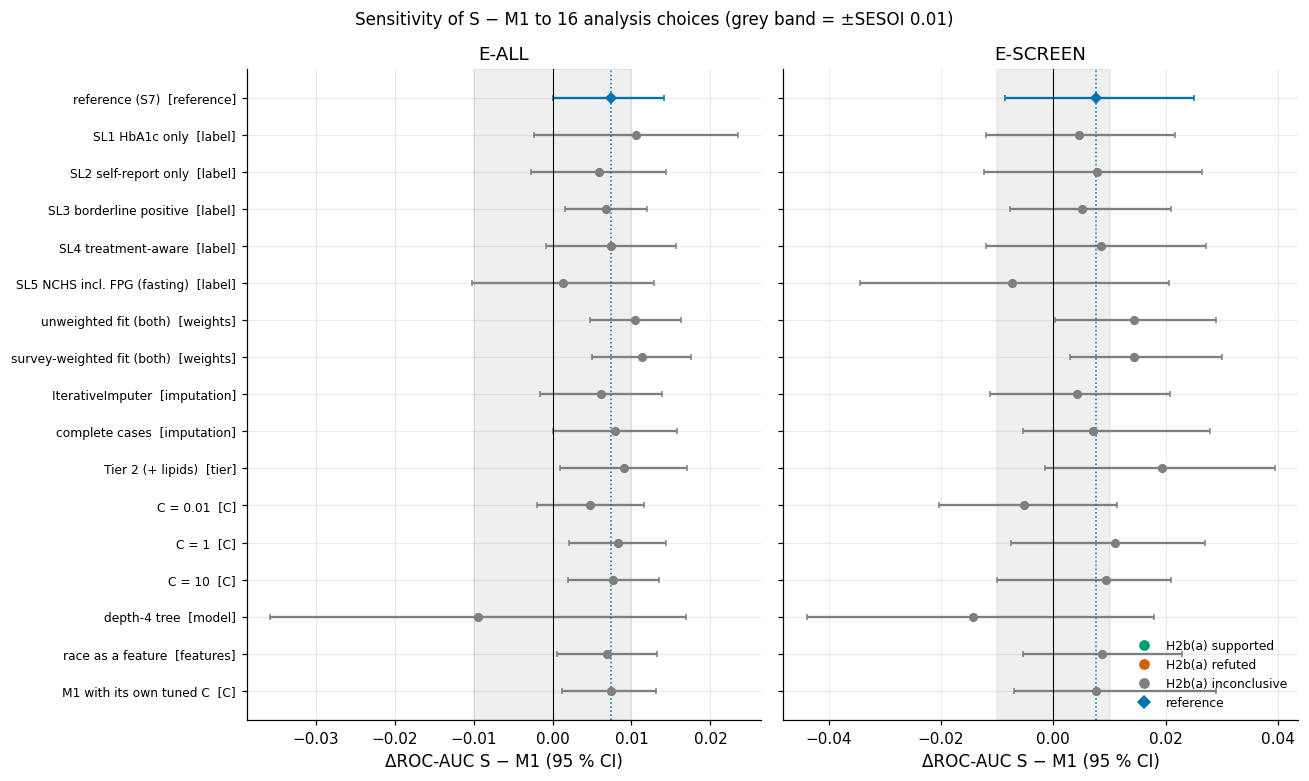

In [8]:
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(12, 7.2), sharey=True)
order = list(dict.fromkeys(sens["spec"]))
groups_ = sens.drop_duplicates("spec").set_index("spec")["group"]
for ax, pop in zip(axes, ("E-ALL", "E-SCREEN")):
    s = sens[sens["pop"] == pop].set_index("spec").loc[order]
    for i, (nm, r) in enumerate(s.iterrows()):
        ax.errorbar(r["est"], i, xerr=[[r["est"] - r["lo"]], [r["hi"] - r["est"]]], fmt="D" if i == 0 else "o",
                    color=OI["blue"] if i == 0 else VCOL[r["h2b"]], capsize=2, ms=5)
    ax.axvspan(-C.SESOI["roc_auc"], C.SESOI["roc_auc"], color=OI["grey"], alpha=0.12)
    ax.axvline(0, color="k", lw=0.7)
    ax.axvline(s["est"].iloc[0], color=OI["blue"], ls=":", lw=1)
    ax.set(title=pop, xlabel="ΔROC-AUC S − M1 (95 % CI)")
axes[0].set_yticks(range(len(order)), [f"{o}  [{groups_[o]}]" for o in order], fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(handles=[Line2D([], [], marker="o", ls="", color=c, label=f"H2b(a) {v}") for v, c in VCOL.items()]
               + [Line2D([], [], marker="D", ls="", color=OI["blue"], label="reference")], fontsize=8, loc="lower right")
fig.suptitle("Sensitivity of S − M1 to 16 analysis choices (grey band = ±SESOI 0.01)", fontsize=11)
fig.tight_layout()
plots.savefig(fig, "S9_sensitivity_forest", caption="F9-2. ΔROC-AUC (S − M1) with conservative 95 % CIs for the reference and 16 one-at-a-time "
              "variations (labels SL1-SL5, fit weights, imputation, tier, C, depth-4 tree, race as a feature, M1 with its own tuned C); "
              "left E-ALL (scored against the row's label), right E-SCREEN. Colour = H2b(a) verdict under the locked equivalence rule.")
plt.show()
S9["sensitivity"] = dict(n_specs=len(SENS), eall_same_verdict=n_same, eall_rows=len(eall),
                         own_C={a: c for a, (c, _) in OWN_C.items()},
                         leak_gate_C0={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_c0},
                         leak_gate_own_C={r["pop"]: {k: r[k] for k in ("est", "lo", "hi")} for r in gate_own},
                         table=sens[["spec", "group", "pop", "n_eval", "n_pos", "auc_a", "auc_b", "est", "lo", "hi", "interval",
                                     "mdd", "h2b"]].round(5).to_dict("records"))

**So what.** Reading the forest plot (numbers in the tables above):

* **The E-ALL verdict does not move.** Every one of the 16 variations gives the same H2b(a) verdict as the reference
  (count printed above): the interval of S − M1 never lies inside ±0.01, and never wholly above +0.01. No variation
  produces an interval wholly below 0, i.e. S is never decisively *worse* than M1.
* **Labels and weighting move the estimate most.** Weighting *both* arms the same way (unweighted or survey-weighted)
  enlarges the S advantage to about +0.01 with an interval excluding 0 – part of the reference gap is S's own survey
  weighting costing it unweighted AUC (B6b). The label changes the size of the gap (HbA1c-only largest, NCHS SL5 on the
  fasting half smallest and widest), not its direction on E-ALL.
* **The depth-4 tree is the only model-class change, and it reverses the sign** (with a wide interval): for a tree the
  systematic steps (scaling, splines, one-hot rules) are irrelevant (B5-e), so S − M1 there only measures noise in two
  unstable trees – one more reason the tree is a probe, not the model.
* **The C0 bias is nil here.** Tuned on their own, M0 and M1 pick the same C as S (printed), so "M1 with its own C"
  reproduces the reference and the leak gate M1 − M0 is unchanged: the HR2 rule "same model for every arm" did not
  favour S or manufacture the leakage drop.
* **E-SCREEN**: all intervals are wide (about 25 positives per fold) and every verdict is inconclusive; point estimates
  range around zero, the screening value of the extra preparation is not established either way.